In [1]:
%pip install opencv-python numpy matplotlib scikit-image ultralytics

  Using cached ultralytics-8.4.182-py3-none-any.whl.metadata (46 kB)
  Using cached torchvision-0.29.1-cp313-cp313-win_amd64.whl.metadata (5.7 kB)
  Using cached polars-2.0.0-py3-none-any.whl.metadata (11 kB)
  Using cached ultralytics_thop-2.2.2-py3-none-any.whl.metadata (14 kB)
  Using cached ultralytics_platform-0.1.90-py3-none-any.whl.metadata (17 kB)
Using cached ultralytics-8.4.182-py3-none-any.whl (1.4 MB)
Using cached polars-2.0.0-py3-none-any.whl (876 kB)
Using cached torchvision-0.29.1-cp313-cp313-win_amd64.whl (1.4 MB)
Using cached ultralytics_platform-0.1.90-py3-none-any.whl (97 kB)
Using cached ultralytics_thop-2.2.2-py3-none-any.whl (32 kB)

   ---------------------------------------- 0/5 [polars]
   ---------------------------------------- 0/5 [polars]
   ---------------------------------------- 0/5 [polars]
   ---------------------------------------- 0/5 [polars]
   ---------------------------------------- 0/5 [polars]
   ---------------------------------------- 0/5 [po

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage
import ultralytics

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("scikit-image version:", skimage.__version__)

print("\nAll required libraries imported successfully!")

OpenCV version: 5.0.0
NumPy version: 2.1.3
scikit-image version: 0.25.0

All required libraries imported successfully!


# CCA 3: Computer Vision and Digital Image Processing

**Units:** 3, 4 and 5

**Programming Language:** Python

**Libraries:** OpenCV, NumPy, Matplotlib, scikit-image and Ultralytics YOLO

## Task 1: Image Restoration and Segmentation

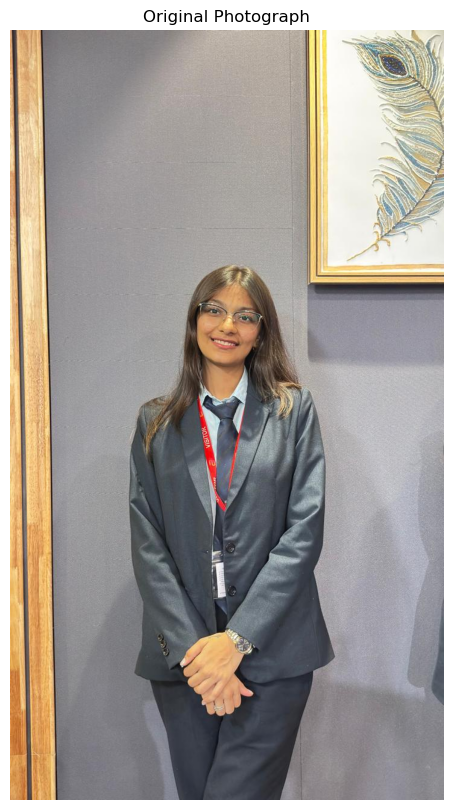

Image loaded successfully!
Image dimensions: (1280, 720, 3)


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Project directory
PROJECT_DIR = Path.cwd()

# Image path
IMAGE_PATH = PROJECT_DIR / "data" / "images" / "original.jpeg"

# Load the original photograph
image = cv2.imread(str(IMAGE_PATH))

if image is None:
    print("Image not found!")
    print("Expected path:", IMAGE_PATH.resolve())
else:
    # Convert BGR to RGB
    original = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Display the photograph
    plt.figure(figsize=(7, 10))
    plt.imshow(original)
    plt.title("Original Photograph")
    plt.axis("off")
    plt.show()

    print("Image loaded successfully!")
    print("Image dimensions:", original.shape)

## Task 1A: Image Restoration
1. Add Gaussian noise and salt-and-pepper noise to the photograph. 

In [10]:
from pathlib import Path

# Create the output directory
OUTPUT_DIR = Path.cwd() / "outputs" / "task1_image_restoration"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder created:", OUTPUT_DIR.resolve())

Output folder created: C:\Users\RADHE\CV-Assignment\outputs\task1_image_restoration


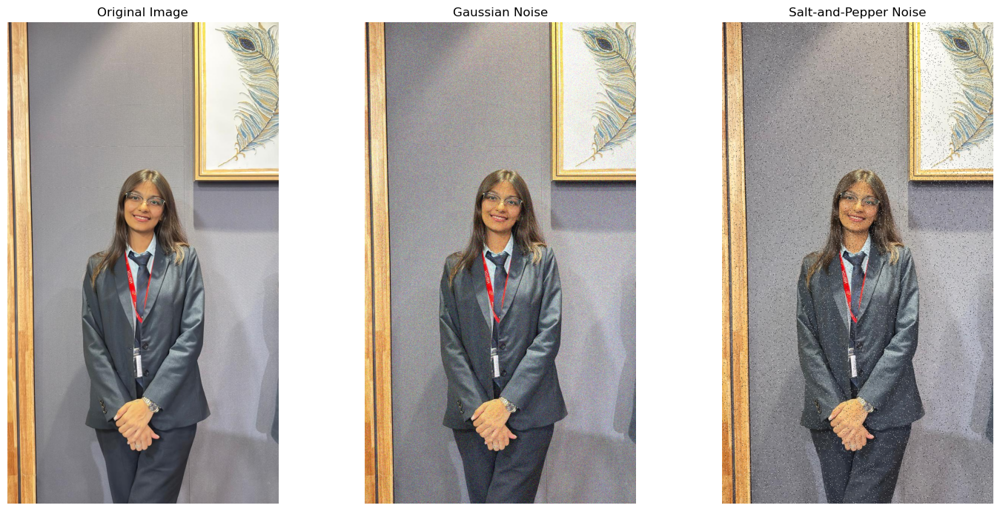

Gaussian noise added successfully.
Salt-and-pepper noise added successfully.
Output images saved in: C:\Users\RADHE\CV-Assignment\outputs\task1_image_restoration


In [9]:
# Task 1A: Adding Noise to the Original Image

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Set random seed for reproducible results
np.random.seed(42)

# Create output directory
OUTPUT_DIR = Path.cwd() / "outputs" / "task1_image_restoration"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Get image dimensions
height, width, channels = original.shape

# -----------------------------------
# 1. Gaussian Noise
# -----------------------------------

gaussian_noise = np.random.normal(
    0, 20, original.shape
)

gaussian_noisy = np.clip(
    original.astype(np.float32) + gaussian_noise,
    0, 255
).astype(np.uint8)

# -----------------------------------
# 2. Salt-and-Pepper Noise
# -----------------------------------

salt_pepper_noisy = original.copy()

noise_amount = 0.04
num_pixels = int(noise_amount * height * width)

# Add white pixels (salt)
num_salt = num_pixels // 2

salt_y = np.random.randint(0, height, num_salt)
salt_x = np.random.randint(0, width, num_salt)

salt_pepper_noisy[salt_y, salt_x] = 255

# Add black pixels (pepper)
num_pepper = num_pixels - num_salt

pepper_y = np.random.randint(0, height, num_pepper)
pepper_x = np.random.randint(0, width, num_pepper)

salt_pepper_noisy[pepper_y, pepper_x] = 0

# -----------------------------------
# 3. Display Comparison
# -----------------------------------

plt.figure(figsize=(15, 7))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gaussian_noisy)
plt.title("Gaussian Noise")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(salt_pepper_noisy)
plt.title("Salt-and-Pepper Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

# -----------------------------------
# 4. Save Output Images
# -----------------------------------

plt.imsave(OUTPUT_DIR / "original.png", original)
plt.imsave(OUTPUT_DIR / "gaussian_noise.png", gaussian_noisy)
plt.imsave(OUTPUT_DIR / "salt_pepper_noise.png", salt_pepper_noisy)

print("Gaussian noise added successfully.")
print("Salt-and-pepper noise added successfully.")
print("Output images saved in:", OUTPUT_DIR.resolve())

2. Apply median filtering and Gaussian filtering to restore the noisy images.

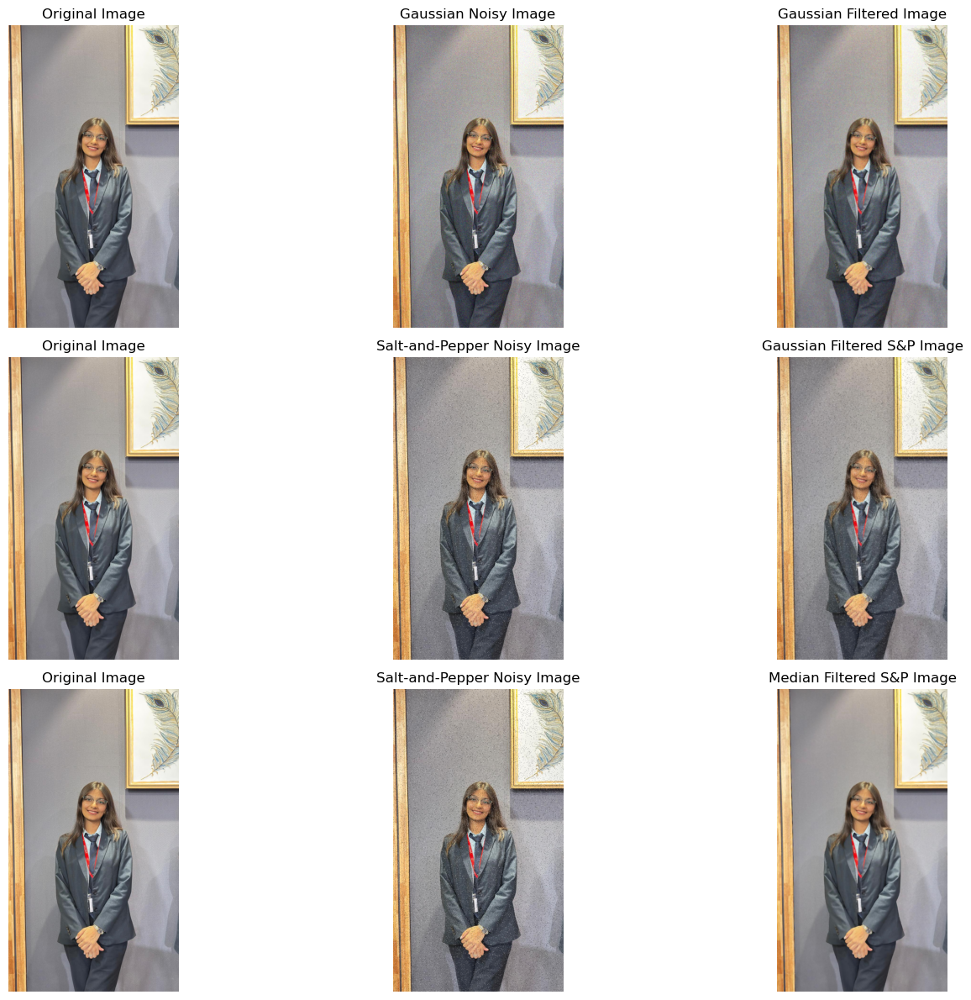

Gaussian filtering completed.
Median filtering completed.
All restored images saved successfully.
Output folder: C:\Users\RADHE\CV-Assignment\outputs\task1_image_restoration


In [11]:
# Task 1A: Image Restoration Using Median and Gaussian Filters

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Create output directory
OUTPUT_DIR = Path.cwd() / "outputs" / "task1_image_restoration"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------
# 1. Gaussian Filtering
# ------------------------------------------

# Restore Gaussian noisy image
gaussian_restored = cv2.GaussianBlur(
    gaussian_noisy,
    (5, 5),
    1.0
)

# Restore salt-and-pepper noisy image
gaussian_filtered_sp = cv2.GaussianBlur(
    salt_pepper_noisy,
    (5, 5),
    1.0
)

# ------------------------------------------
# 2. Median Filtering
# ------------------------------------------

# Restore Gaussian noisy image
median_restored = cv2.medianBlur(
    gaussian_noisy,
    5
)

# Restore salt-and-pepper noisy image
median_filtered_sp = cv2.medianBlur(
    salt_pepper_noisy,
    5
)

# ------------------------------------------
# 3. Display the Results
# ------------------------------------------

plt.figure(figsize=(16, 12))

plt.subplot(3, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(3, 3, 2)
plt.imshow(gaussian_noisy)
plt.title("Gaussian Noisy Image")
plt.axis("off")

plt.subplot(3, 3, 3)
plt.imshow(gaussian_restored)
plt.title("Gaussian Filtered Image")
plt.axis("off")

plt.subplot(3, 3, 4)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(3, 3, 5)
plt.imshow(salt_pepper_noisy)
plt.title("Salt-and-Pepper Noisy Image")
plt.axis("off")

plt.subplot(3, 3, 6)
plt.imshow(gaussian_filtered_sp)
plt.title("Gaussian Filtered S&P Image")
plt.axis("off")

plt.subplot(3, 3, 7)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(3, 3, 8)
plt.imshow(salt_pepper_noisy)
plt.title("Salt-and-Pepper Noisy Image")
plt.axis("off")

plt.subplot(3, 3, 9)
plt.imshow(median_filtered_sp)
plt.title("Median Filtered S&P Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------
# 4. Save Restored Images
# ------------------------------------------

plt.imsave(OUTPUT_DIR / "gaussian_filtered.png", gaussian_restored)
plt.imsave(OUTPUT_DIR / "median_filtered_gaussian.png", median_restored)
plt.imsave(OUTPUT_DIR / "gaussian_filtered_salt_pepper.png", gaussian_filtered_sp)
plt.imsave(OUTPUT_DIR / "median_filtered_salt_pepper.png", median_filtered_sp)

print("Gaussian filtering completed.")
print("Median filtering completed.")
print("All restored images saved successfully.")
print("Output folder:", OUTPUT_DIR.resolve())

4. Calculate PSNR and SSIM where applicable. 


In [12]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import pandas as pd

# Images to compare with the original
images = {
    "Gaussian Noisy": gaussian_noisy,
    "Gaussian Filtered": gaussian_restored,
    "Median Filtered (Gaussian Noise)": median_restored,
    "Salt-and-Pepper Noisy": salt_pepper_noisy,
    "Gaussian Filtered (Salt-and-Pepper)": gaussian_filtered_sp,
    "Median Filtered (Salt-and-Pepper)": median_filtered_sp
}

results = []

for name, img in images.items():
    psnr = peak_signal_noise_ratio(original, img, data_range=255)

    ssim = structural_similarity(
        original,
        img,
        channel_axis=-1,
        data_range=255
    )

    results.append({
        "Image": name,
        "PSNR (dB)": round(psnr, 2),
        "SSIM": round(ssim, 4)
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)

# Save results
comparison_df.to_csv(
    OUTPUT_DIR / "restoration_metrics.csv",
    index=False
)

print("PSNR and SSIM calculated and saved successfully.")

,Image,PSNR (dB),SSIM
0,Gaussian Noisy,22.23,0.3343
1,Gaussian Filtered,28.59,0.6943
2,Median Filtered (Gaussian Noise),27.12,0.6534
3,Salt-and-Pepper Noisy,19.39,0.3794
4,Gaussian Filtered (Salt-and-Pepper),27.18,0.6278
5,Median Filtered (Salt-and-Pepper),28.30,0.7797


PSNR and SSIM calculated and saved successfully.


### B. Morphological Processing and Segmentation 

5. Convert a suitable image into a binary image using thresholding. 


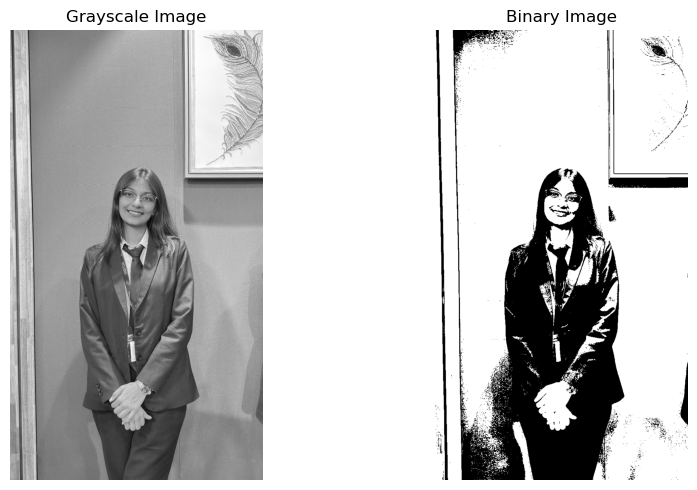

In [14]:
# Convert RGB image to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

# Apply binary thresholding
_, binary = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY
)

# Display results
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save output
plt.imsave(OUTPUT_DIR / "binary_image.png", binary, cmap="gray")

6. Apply erosion, dilation, opening and closing. 


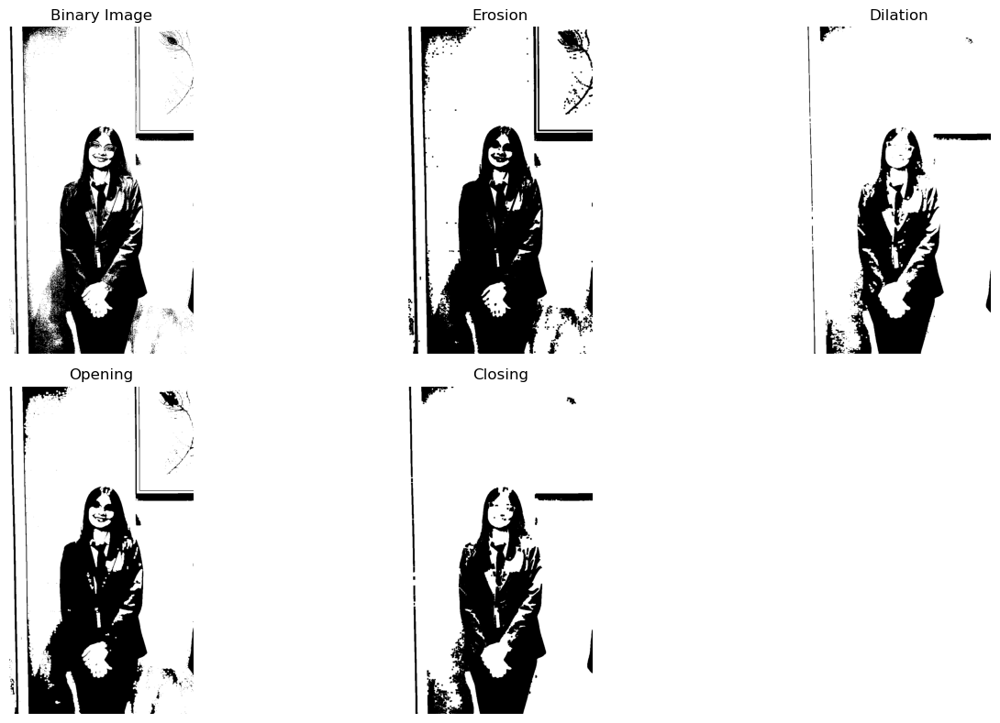

Morphological operations completed.


In [15]:
# Create a morphological kernel
kernel = np.ones((5, 5), np.uint8)

# Apply morphological operations
erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# Display results
images = [
    (binary, "Binary Image"),
    (erosion, "Erosion"),
    (dilation, "Dilation"),
    (opening, "Opening"),
    (closing, "Closing")
]

plt.figure(figsize=(14, 8))

for i, (img, title) in enumerate(images, 1):
    plt.subplot(2, 3, i)
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Save outputs
for img, title in images[1:]:
    filename = title.lower() + ".png"
    cv2.imwrite(str(OUTPUT_DIR / filename), img)

print("Morphological operations completed.")

7. Apply Canny edge detection. 


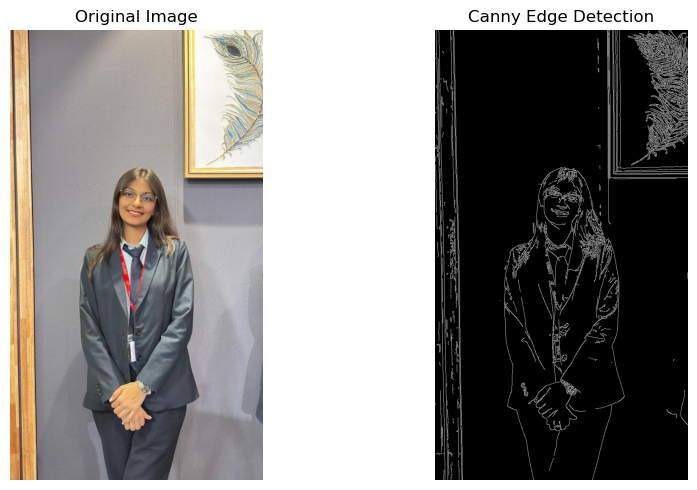

Canny edge detection completed.


In [16]:
# Apply Canny edge detection
edges = cv2.Canny(gray, 100, 200)

# Display results
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save output
cv2.imwrite(str(OUTPUT_DIR / "canny_edges.png"), edges)

print("Canny edge detection completed.")

8. Perform watershed segmentation on a suitable image containing multiple or touching objects. 


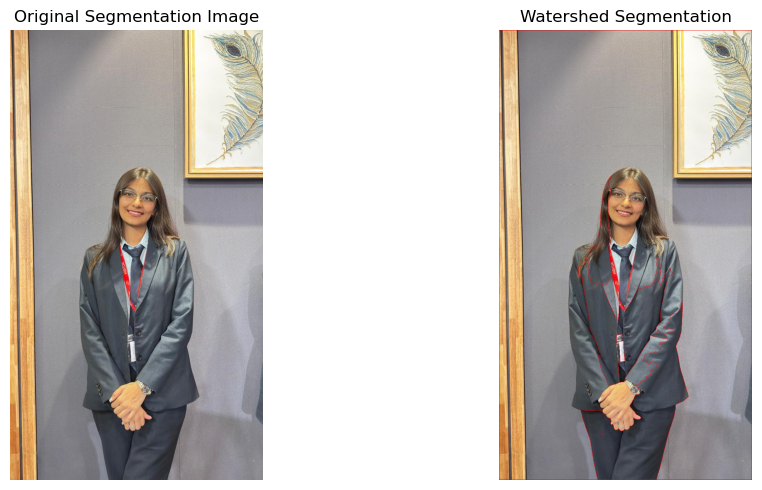

Watershed segmentation completed.


In [18]:
# Load a suitable image containing multiple objects

SEGMENTATION_PATH = Path.cwd() / "data" / "images" / "original.jpeg"
seg_image = cv2.imread(str(SEGMENTATION_PATH))

if seg_image is None:
    raise FileNotFoundError(
        f"Please save a suitable image at: {SEGMENTATION_PATH}"
    )

# Convert BGR to RGB for display
seg_rgb = cv2.cvtColor(seg_image, cv2.COLOR_BGR2RGB)

# Convert to grayscale and apply Otsu thresholding
seg_gray = cv2.cvtColor(seg_image, cv2.COLOR_BGR2GRAY)
_, thresh = cv2.threshold(
    seg_gray, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Remove small noise
kernel = np.ones((3, 3), np.uint8)
opening_ws = cv2.morphologyEx(
    thresh, cv2.MORPH_OPEN, kernel, iterations=2
)

# Identify background
sure_bg = cv2.dilate(opening_ws, kernel, iterations=3)

# Identify foreground
dist_transform = cv2.distanceTransform(
    opening_ws, cv2.DIST_L2, 5
)

_, sure_fg = cv2.threshold(
    dist_transform,
    0.4 * dist_transform.max(),
    255,
    0
)

sure_fg = np.uint8(sure_fg)

# Identify uncertain regions
unknown = cv2.subtract(sure_bg, sure_fg)

# Create markers
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

# Apply watershed
markers = cv2.watershed(seg_image, markers)

# Mark boundaries in red
watershed_result = seg_rgb.copy()
watershed_result[markers == -1] = [255, 0, 0]

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(seg_rgb)
plt.title("Original Segmentation Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(watershed_result)
plt.title("Watershed Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save output
plt.imsave(
    OUTPUT_DIR / "watershed_segmentation.png",
    watershed_result
)

print("Watershed segmentation completed.")

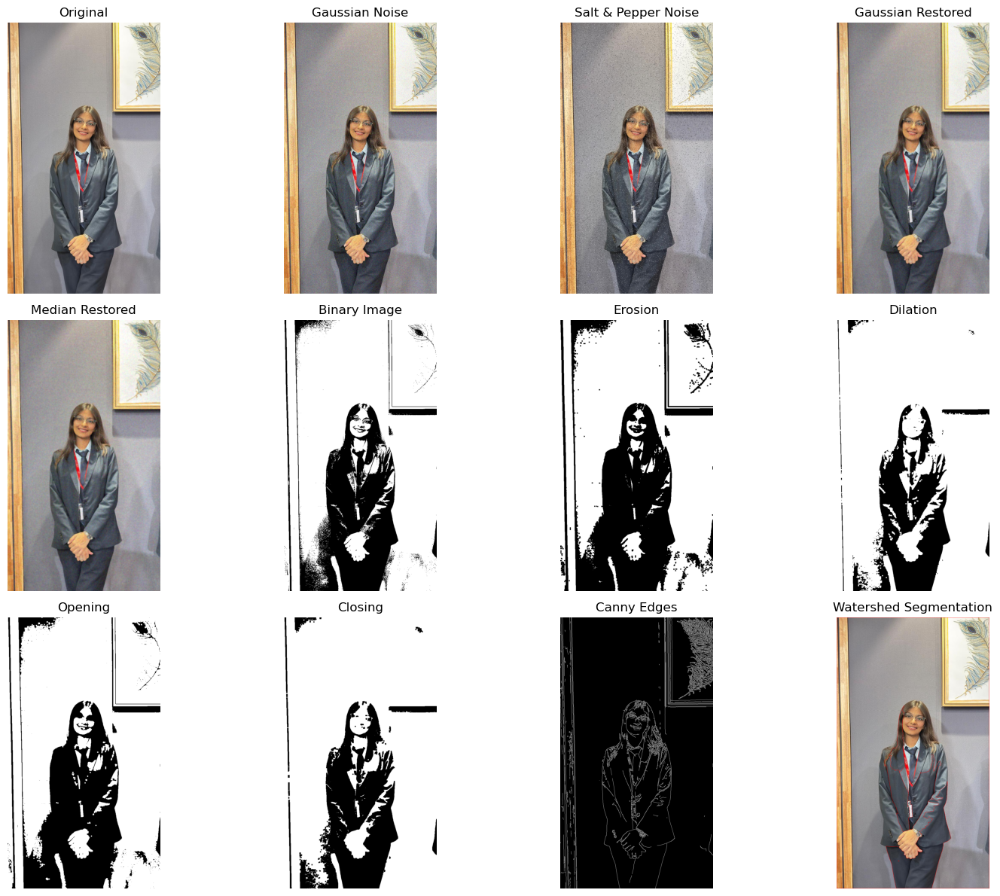

In [21]:
import matplotlib.pyplot as plt

images = [
    ("Original", original),
    ("Gaussian Noise", gaussian_noisy),
    ("Salt & Pepper Noise", salt_pepper_noisy),
    ("Gaussian Restored", gaussian_restored),
    ("Median Restored", median_restored),
    ("Binary Image", binary),
    ("Erosion", erosion),
    ("Dilation", dilation),
    ("Opening", opening),
    ("Closing", closing),
    ("Canny Edges", edges),
    ("Watershed Segmentation", watershed_result)
]

plt.figure(figsize=(16, 12))

for i, (title, img) in enumerate(images):
    plt.subplot(3, 4, i + 1)
    plt.imshow(img, cmap="gray" if img.ndim == 2 else None)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Conclusion

The results show that different image processing techniques are useful for different purposes. Gaussian noise adds smooth random variations, while salt-and-pepper noise creates distinct black and white spots. Gaussian filtering reduces Gaussian noise but slightly blurs image details, whereas median filtering is more effective at removing salt-and-pepper noise while preserving edges.

Binary thresholding converts the grayscale image into black and white regions. Erosion reduces white regions, dilation expands them, opening removes small white noise, and closing fills small gaps. Canny edge detection highlights the boundaries and outlines of objects. Watershed segmentation identifies regions in the image, although it does not clearly separate objects in this particular image.

Overall, **median filtering is effective for salt-and-pepper noise, Gaussian filtering is suitable for Gaussian noise, and Canny is useful for edge detection**. The effectiveness of thresholding, morphological operations, and watershed segmentation depends on the image and the selected parameters.


# Task 2: Feature Extraction and Image Matching


1. Extract and visualize Histogram of Oriented Gradients (HOG) features. 


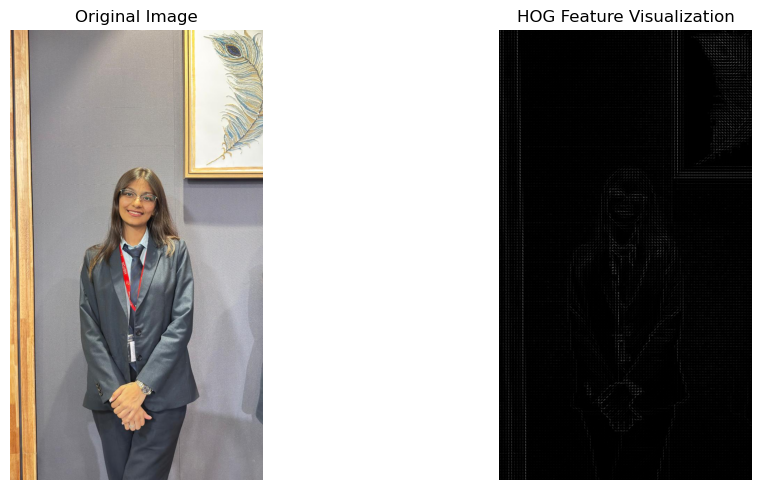

HOG feature vector shape: (509436,)


In [22]:
import cv2
import matplotlib.pyplot as plt
from skimage.feature import hog

# Convert image to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

# Extract HOG features
hog_features, hog_image = hog(
    gray,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

# Display original and HOG images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_image, cmap="gray")
plt.title("HOG Feature Visualization")
plt.axis("off")

plt.tight_layout()
plt.show()

print("HOG feature vector shape:", hog_features.shape)

2. Detect SIFT keypoints and calculate descriptors. 

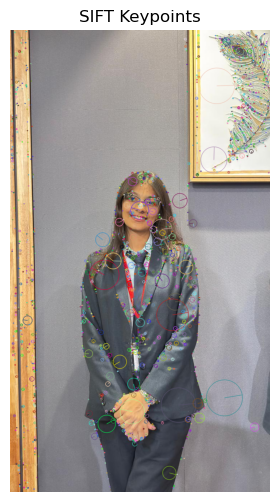

Number of keypoints detected: 1884
Descriptor shape: (1884, 128)


In [32]:
import cv2
import matplotlib.pyplot as plt

# Convert the original image to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and calculate descriptors
keypoints, descriptors = sift.detectAndCompute(gray, None)

# Draw keypoints on the original image
sift_image = cv2.drawKeypoints(
    original,
    keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Display the image with keypoints
plt.figure(figsize=(10, 6))
plt.imshow(sift_image)
plt.title("SIFT Keypoints")
plt.axis("off")
plt.show()

# Display results
print("Number of keypoints detected:", len(keypoints))
print("Descriptor shape:", descriptors.shape if descriptors is not None else None)

3. Match the SIFT features between the two images. 

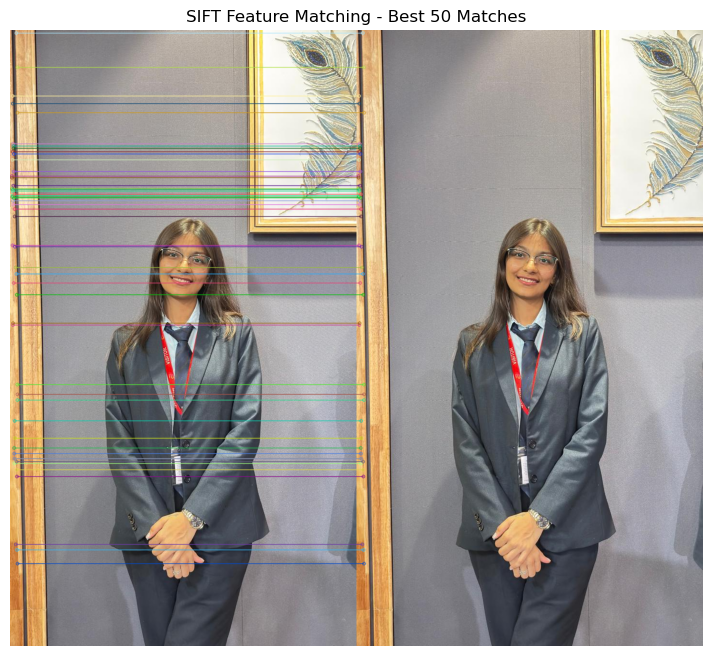

Keypoints in Image 1: 1884
Keypoints in Image 2: 1884
Good matches displayed: 50


In [31]:
import cv2
import matplotlib.pyplot as plt

# Load the two images
img1 = original.copy()
img2_color = cv2.imread("data/images/second.jpeg")

if img2_color is None:
    raise FileNotFoundError("Check the path to second.jpeg")

gray1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(img2_color, cv2.COLOR_BGR2GRAY)

# Detect SIFT features
sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)

# Match descriptors using KNN
bf = cv2.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

# Apply a stricter Lowe's ratio test
good_matches = [
    m for m, n in matches
    if m.distance < 0.6 * n.distance
]

# Keep only the 50 best matches
good_matches = sorted(good_matches, key=lambda x: x.distance)[:50]

# Draw matches
matched_image = cv2.drawMatches(
    img1, kp1,
    cv2.cvtColor(img2_color, cv2.COLOR_BGR2RGB), kp2,
    good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Display results
plt.figure(figsize=(16, 8))
plt.imshow(matched_image)
plt.title("SIFT Feature Matching - Best 50 Matches")
plt.axis("off")
plt.show()

print("Keypoints in Image 1:", len(kp1))
print("Keypoints in Image 2:", len(kp2))
print("Good matches displayed:", len(good_matches))
matched_image_task3 = matched_image.copy()

4. Repeat the matching experiment after rotating or resizing one image. 

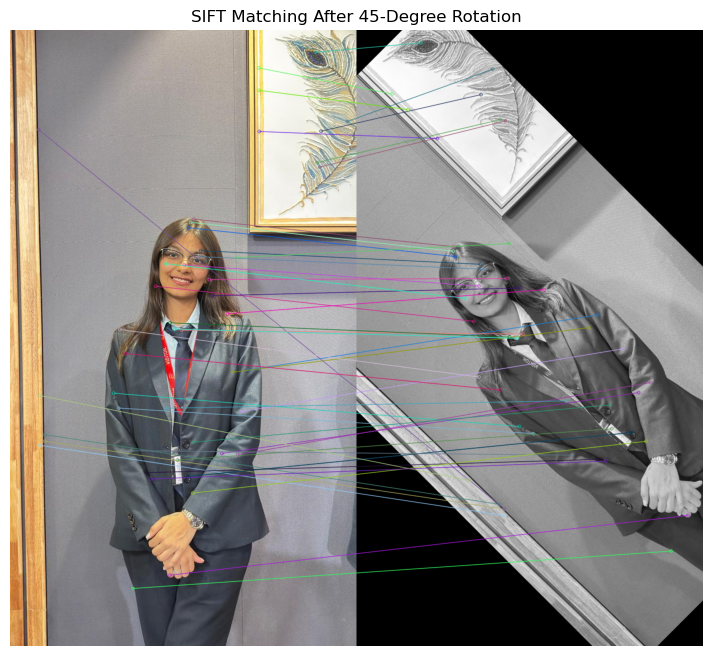

Original keypoints: 1884
Rotated keypoints: 2088
Good matches: 50


In [33]:
import cv2
import matplotlib.pyplot as plt

# Original image
img1 = original.copy()
gray1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY)

# Rotate the image by 45 degrees
h, w = gray1.shape
center = (w // 2, h // 2)

matrix = cv2.getRotationMatrix2D(center, 45, 1.0)
rotated = cv2.warpAffine(gray1, matrix, (w, h))

# Detect SIFT features
sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(rotated, None)

# Match features
bf = cv2.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

# Apply Lowe's ratio test
good_matches = [
    m for m, n in matches
    if m.distance < 0.7 * n.distance
]

# Display the 50 best matches
good_matches = sorted(good_matches, key=lambda x: x.distance)[:50]

matched_image = cv2.drawMatches(
    img1, kp1,
    cv2.cvtColor(rotated, cv2.COLOR_GRAY2RGB), kp2,
    good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Display results
plt.figure(figsize=(16, 8))
plt.imshow(matched_image)
plt.title("SIFT Matching After 45-Degree Rotation")
plt.axis("off")
plt.show()

print("Original keypoints:", len(kp1))
print("Rotated keypoints:", len(kp2))
print("Good matches:", len(good_matches))
matched_image_task4 = matched_image.copy()

5. Display and compare the matching results. 

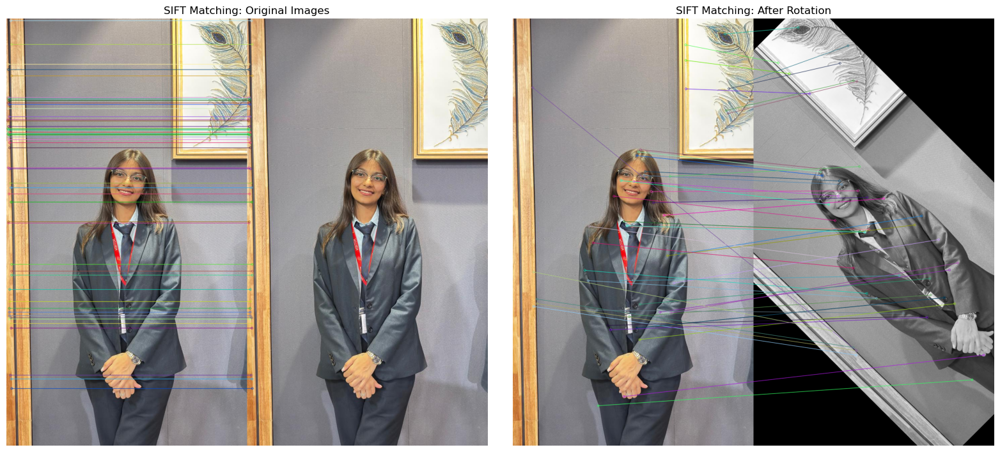

In [35]:
plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
plt.imshow(matched_image_task3)
plt.title("SIFT Matching: Original Images")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(matched_image_task4)
plt.title("SIFT Matching: After Rotation")
plt.axis("off")

plt.tight_layout()
plt.show()

# Task 3: Object Recognition Using Viola–Jones and YOLO

1. Apply a pretrained Haar cascade classifier to detect faces or another supported object. 


In [39]:
import urllib.request

url = "https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml"

urllib.request.urlretrieve(
    url,
    "haarcascade_frontalface_default.xml"
)

print("Haar cascade downloaded successfully!")

Haar cascade downloaded successfully!


In [42]:
import cv2

face_cascade = cv2.CascadeClassifier(
    "haarcascade_frontalface_default.xml"
)

print("Classifier loaded:", not face_cascade.empty())

Classifier loaded: True


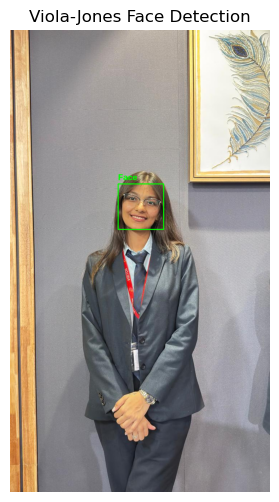

Number of faces detected: 1


In [43]:
import cv2
import matplotlib.pyplot as plt

# 1. Load the photograph
image = cv2.imread("data/images/original.jpeg")

if image is None:
    raise FileNotFoundError("Check the path to original.jpeg")

# 2. Convert the image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# 3. Load the pretrained Haar cascade classifier
face_cascade = cv2.CascadeClassifier(
    "haarcascade_frontalface_default.xml"
)

if face_cascade.empty():
    raise ValueError("Haar cascade classifier could not be loaded.")

# 4. Detect faces
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

# 5. Draw bounding boxes around detected faces
result = image.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        result,
        "Face",
        (x, y - 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

# 6. Display the result
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Viola-Jones Face Detection")
plt.axis("off")
plt.show()

print("Number of faces detected:", len(faces))

2. Apply a pretrained YOLO model to detect supported objects. 


In [1]:
from ultralytics import YOLO

# Load a pretrained YOLO model
model = YOLO("yolov8n.pt")

print("Pretrained YOLO model loaded successfully!")

Pretrained YOLO model loaded successfully!


In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load the input image
image = cv2.imread("data/images/original.jpeg")

if image is None:
    raise FileNotFoundError("Check the path to original.jpeg")

# Perform object detection
results = model(image)

# Display the detected objects
result_image = results[0].plot()

# Convert BGR to RGB for correct display in Matplotlib
result_image = cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(result_image)
plt.title("YOLO Object Detection")
plt.axis("off")
plt.show()


0: 640x384 1 person, 1 tie, 118.5ms
Speed: 9.1ms preprocess, 118.5ms inference, 13.2ms postprocess per image at shape (1, 3, 640, 384)


In [ ]:
import cv2
from ultralytics import YOLO

# Load the pretrained YOLO model
model = YOLO("yolov8n.pt")

# Load the image
image = cv2.imread("data/images/original.jpeg")

if image is None:
    raise FileNotFoundError("Check the path to original.jpeg")

# Detect objects and store the results
results = model(image)

# Display detections
result_image = results[0].plot()
result_image = cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
plt.imshow(result_image)
plt.title("YOLO Object Detection")
plt.axis("off")
plt.show()


0: 640x384 1 person, 1 tie, 65.6ms
Speed: 3.6ms preprocess, 65.6ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 384)
